# k-Nearest Neighbor Klassifikator

Folgendes Diagram zeigt 2D Merkmalvektoren der Klassen "Zahlen" und "Buchstaben" in Form von Zahlen (1-5) und Buchstaben (a-f)


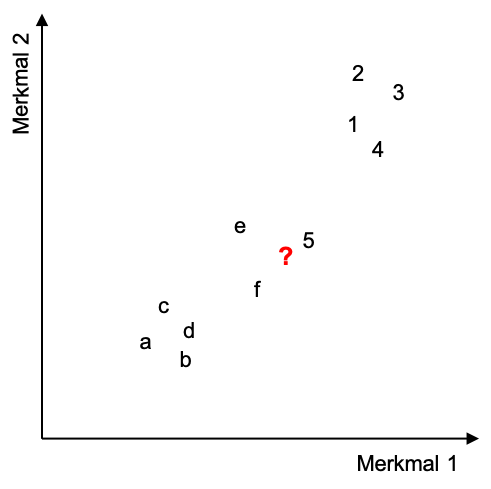

Als Distanzmaß wird der Euklidabstand verwendet.

a) Welche Klasse wird <font color='red'>?</font> bei einem 1-NN Klassifikator zugeweisen?

b) Welche Klasse wird <font color='red'>?</font> bei einem 3-NN Klassifikator zugeweisen?

c) Geben Sie an, wie sich im Falle des 3-NN Klassifikators eine Rückweisung implementieren lässt? Welchen Wert hätte <font color='red'>?</font> in diesem Fall? 

d) Beim kNN Klassifikator müssen die gesamten Trainingsdaten im Speicher gehalten werden. Zur Klassifikation müssen Distanzen für alle Trainingsbeispiele berechnet werden. <br>
  > d1) Wie könnte dieses "Effizienzproblem" gelöst werden? <br>
  > d2) Welche Nachteile hat die Methode aus d1? <br>

a) Klasse Zahlen

b) Klasse Buchstaben

c.I) Fall: 2 Klassen, dann ist eine Rückweisung nicht sinnvoll, denn eine Kombination aus 3 Nachbarn mit 2 Klassen wird immmer eine Mehrheit ergeben.

Daher hätte ? in diesem Fall trotzdem die Klasse Buchstaben.


c.II) Fall: 3 Klassen oder mehr.

Beispiel: Klassen J, K, L

Es müssen mindestens zwei Nachbarn zustimmen, sonst wird der Wert NIL zurückgegeben.

II.1] Nachbarn (K, J, L) => NIL

II.2] Nachbarn (J, L, J) => J

und so weiter


### d (TODO)


# Implementieren des kNN Klassifikators in Python

Implementieren Sie eine Klasse MyKNN, die einen kNN Klassifikator definieren soll. Als Abstandsmaß ist Euklid-Abstand zu implementieren. 

Verwenden Sie die Struktur wie in sklearn:
- Klassifikatoren werden als Klasse repraesentiert
- Es gibt eine fit()- und eine predict()-Methode

In [1]:
import ctypes

haneul = ctypes.CDLL("./libhaneul.so")

haneul.sort_keys.argtypes = [
    ctypes.POINTER(ctypes.c_uint32),
    ctypes.c_size_t
]

haneul.sort_keys.restype = None

UInt64Ptr = ctypes.POINTER(ctypes.c_uint64)

haneul.view_internal.argtypes = [
    ctypes.POINTER(UInt64Ptr),
    ctypes.c_size_t
]

haneul.view_internal.restype = ctypes.c_bool

haneul.distance_loop.argtypes = [
    ctypes.POINTER(ctypes.c_float),
    ctypes.POINTER(ctypes.c_double),
    ctypes.POINTER(ctypes.c_double),

    ctypes.c_size_t,
    ctypes.c_size_t
]
haneul.distance_loop.restype = None

haneul.fit.argtypes = [
    ctypes.POINTER(ctypes.c_double),
    ctypes.POINTER(ctypes.c_int64),
    ctypes.c_size_t, # width
    ctypes.c_size_t,  # height_src
    ctypes.c_size_t,  # max_label
]

haneul.predict.argtypes = [
    ctypes.POINTER(ctypes.c_double),
    ctypes.c_size_t, # width
    ctypes.c_size_t,  # height_new 
    ctypes.c_size_t,  # k_limit
]
haneul.predict.restype = ctypes.POINTER(ctypes.c_int64)

In [2]:

"""
import numpy as np
from math import sqrt

haneul.init_knn()

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.data = None
        self.labels = None
        self.keys = None
        self.transient_results = None
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0
        
        self.data = np.ascontiguousarray(data, dtype=np.float64)
        self.labels = labels

        # used for returning values (and observing them)
        # the values live until predict() is called again
        # clone contents if you want to you want to keep them around.
        self.transient_results = np.zeros(self.data.shape[0], dtype=np.int64)
            
        # reusable container for sorting:
        self.keys = np.zeros(self.data.shape[0], dtype=np.float32)
        
    def predict(self, new_data: np.ndarray):
        
        # TODO(yousef): new predictions should be added to self.data, self.labels
        assert new_data.shape[0] > 0
        assert new_data.shape[1] == self.data.shape[1]

        if len(new_data) > len(self.transient_results):
            self.transient_results = np.resize(self.transient_results, (len(new_data),))
            
        
        ref = self.data
        for res_at, vec in enumerate(new_data):
            dist_ptr =  self.keys.ctypes.data_as(ctypes.POINTER(ctypes.c_float))
            data_ptr = self.data.ctypes.data_as(ctypes.POINTER(ctypes.c_double))
            vec_ptr = vec.ctypes.data_as(ctypes.POINTER(ctypes.c_double))
            width = vec.shape[0]
            height = len(self.data)

            assert self.data.size == width * height
            haneul.distance_loop(dist_ptr, data_ptr, vec_ptr, width, height);
            
            # for vec: distance [i] = calc(ref[i] - vec)
            
            
            # reinterpret floats as u32 (without copying)
            keys_u32 = self.keys.view(np.uint32)
            
            keys_ptr = keys_u32.ctypes.data_as(ctypes.POINTER(ctypes.c_uint32))
            len_keys = len(keys_u32) 
            
            haneul.sort_keys(keys_ptr, len_keys);
            
            # read indices without copying
            indices_view = ()
            length = ctypes.c_size_t(len_keys) 
            haneul.view_internal(ctypes.byref(indices_view), length)
            indices = np.ctypeslib.as_array(indices_view, shape=(len_keys,))

            k_labels = [self.labels[i] for i in indices[:self.k+1]]
            
            counts = np.bincount(k_labels)
            max_label = np.argmax(counts)
            
            self.transient_results[res_at] = max_label

        return self.transient_results

"""

'\nimport numpy as np\nfrom math import sqrt\n\nhaneul.init_knn()\n\nclass MyKNN:\n    def __init__(self, target_names, k=1):\n        self.label_names = target_names\n        self.k = k\n        self.data = None\n        self.labels = None\n        self.keys = None\n        self.transient_results = None\n\n    def fit(self, data: np.ndarray, labels: np.ndarray): \n        assert len(data.shape) == 2\n        assert len(labels.shape) == 1\n        assert data.shape[0] == labels.shape[0]\n        assert data.shape[0] > 0\n\n        self.data = np.ascontiguousarray(data, dtype=np.float64)\n        self.labels = labels\n\n        # used for returning values (and observing them)\n        # the values live until predict() is called again\n        # clone contents if you want to you want to keep them around.\n        self.transient_results = np.zeros(self.data.shape[0], dtype=np.int64)\n\n        # reusable container for sorting:\n        self.keys = np.zeros(self.data.shape[0], dtype=np.flo

In [3]:
import numpy as np
from math import sqrt

haneul.init_knn()

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.width = 0
        self.height_src = 0
        
        # used for returning values (and observing them)
        # the values live until predict() is called again
        # clone contents if you want to you want to keep them around.
        self.transient_results = None
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0

        data = np.ascontiguousarray(data, dtype=np.float64)
        data_ptr = data.ctypes.data_as(ctypes.POINTER(ctypes.c_double))

        labels_ptr = labels.ctypes.data_as(ctypes.POINTER(ctypes.c_int64))
        
        self.width = (data.shape[1])
        self.height_src = (data.shape[0])
        
        max_label = ctypes.c_size_t(100)
        ret = haneul.fit(data_ptr, labels_ptr, ctypes.c_size_t(self.width), ctypes.c_size_t(self.height_src), max_label)
        assert ret

        
    def predict(self, new_data: np.ndarray):
        assert new_data.flags["C_CONTIGUOUS"]
        # TODO(yousef): new predictions should be added to self.data, self.labels
        assert new_data.shape[0] > 0
        assert new_data.shape[1] == self.width

        new_data_ptr = new_data.ctypes.data_as(ctypes.POINTER(ctypes.c_double));
        width = ctypes.c_size_t(new_data.shape[1])
        height = ctypes.c_size_t(new_data.shape[0])
        k_limit = ctypes.c_size_t(self.k) 
        
        results = haneul.predict(new_data_ptr, width, height, k_limit);
        
        array = np.ctypeslib.as_array(results, shape=(new_data.shape[0],))
        return array

## Testen Sie das Verfahren auf Datensätzen Ihrer Wahl, z.B. 
- Iris-data
- Digit-data
- Wine-data
von sklearn


Zunächst Training = Test

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=10000,
    n_features=2,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

yousef_knn = MyKNN(None, k=11)
yousef_knn.fit(X, y)

x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.arange(x1_min, x1_max, 0.1),
    np.arange(x2_min, x2_max, 0.1)
)

grid_points = np.c_[xx1.ravel(), xx2.ravel()]

print(grid_points.shape)

(70272, 2)


CPU times: user 26.6 s, sys: 2.22 ms, total: 26.6 s
Wall time: 26.6 s


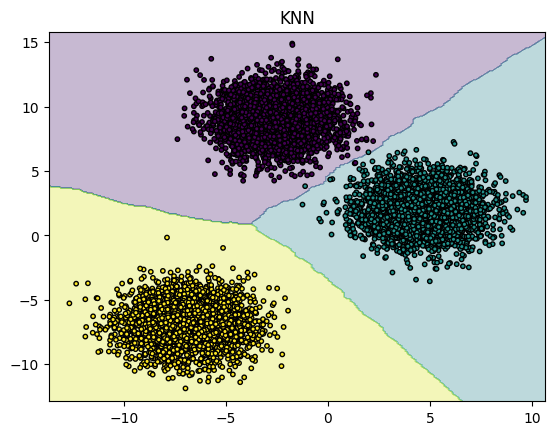

In [5]:
%time Z = yousef_knn.predict(grid_points)

Z = Z.reshape(xx1.shape)

plt.contourf(xx1, xx2, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, s=10, edgecolor='k')

plt.title("KNN")
plt.show()

## Verwenden Sie den Visualisierungscode aus dem Vorlesungs-Notebook um Ihre Implementierung zu testen.

## Bestimmen Sie die Güte Ihres Klassifikators und Testen Sie unterschiedliche Werte für k.

## Zerlegen Sie die Daten in ein Trainings- und Testset und testen Sie erneut.

## Verwenden Sie ein Validierungsset zur Bestimmung eines geeigneten Parameters k

## Verwenden Sie eine Kreuzvalidierung zur Bestimmung von k

